In [1]:
from pathlib import Path 
import requests 

def download_from_github(rel_path, out = None):
    github_raw_base = (
        'https://raw.githubusercontent.com/rasbt/reasoning-from-scratch/refs/heads/main/' 
    )
    
    rel_path = Path(rel_path)
    
    out = Path(out) if out is not None else Path(rel_path.name)
    
    if out.exists():
        size_kb = out.stat().st_size / 1e3
        print(f'{out}: {size_kb:.1f} KB (cached)')
        return out
        
    r = requests.get(github_raw_base + rel_path.as_posix())
    r.raise_for_status()
    
    out.write_bytes(r.content)
    size_kb = out.stat().st_size / 1e3
    print(f'{out}: {size_kb:.1f} KB')

In [2]:
download_from_github(
    'ch06/02_rlvr_grpo_scripts_intro/rlvr_grpo_original_no_kl.py'
)

rlvr_grpo_original_no_kl.py: 15.7 KB (cached)


PosixPath('rlvr_grpo_original_no_kl.py')

In [3]:
# !uv run rlvr_grpo_original_no_kl.py\
#     --steps 500 \
#     --max_new_tokens 512 \
#     --show_eta

In [4]:
download_from_github(
"ch07/02_logs/ch06_rlvr_grpo_original_no_kl_metrics.txt"
)
download_from_github(
"ch07/02_logs/ch06_rlvr_grpo_original_no_kl_metrics.csv"
)

ch06_rlvr_grpo_original_no_kl_metrics.txt: 43.7 KB (cached)
ch06_rlvr_grpo_original_no_kl_metrics.csv: 25.1 KB (cached)


PosixPath('ch06_rlvr_grpo_original_no_kl_metrics.csv')

In [5]:
#       1.Plotting and analyzing basic training metrics

import csv 
import matplotlib.pyplot as plt 

def moving_average(values, window_fraction = 0.25):
    
    window_size = max(1, int(window_fraction * len(values)))
    smoothed = []
    
    for i in range(len(values)):
        start_idx = max(0, i - window_size + 1)
        window_mean = sum(values[start_idx : i + 1]) / (i - start_idx + 1)
        smoothed.append(window_mean)
        
    return smoothed 

def plot_grpo_metrics(csv_path, columns, save_as = None):
    data = {name: {'steps': [], 'values': []} for name in columns}
    
    with Path(csv_path).open(newline = '') as f:
        reader = csv.DictReader(f)
        for row in reader:
            if not row or not row.get('step'):
                continue 
            
            step = int(row['step'])
            
            for name in columns:
                value_str = row.get(name)
                if value_str:
                    data[name]['steps'].append(step)
                    data[name]['values'].append(float(value_str))
                    
    fig, axes = plt.subplots(2, 2, sharex = True, figsize = (6, 4))
    axes = axes.ravel()
    
    for i, name in enumerate(columns):
        steps = data[name]['steps']
        values = data[name]['values']
        
        if not values:
            fig.delaxes(axes[i])
            continue
        
        if name == 'eval_acc':
            axes[i].bar(steps, values, width = 20)
        else:
            axes[i].plot(steps, values, alpha = 0.4)
            axes[i].plot(steps, moving_average(values))
            
        axes[i].set_ylabel(name)
        
    for j in (2, 3):
        if axes[j] in fig.axes:
            axes[j].set_xlabel('step')
            
    plt.tight_layout()
    if save_as is not None:
        plt.savefig(save_as)
    plt.show()

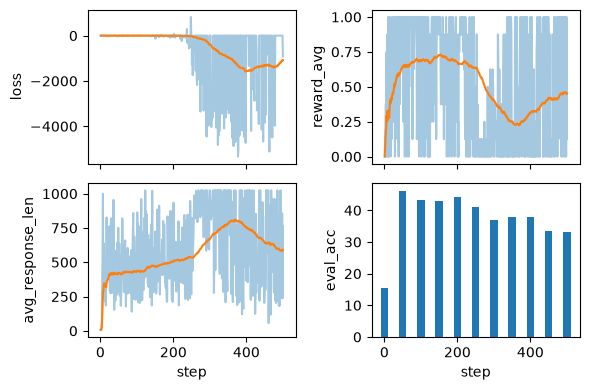

In [6]:
plot_grpo_metrics(
    'ch06_rlvr_grpo_original_no_kl_metrics.csv',
    columns = ['loss', 'reward_avg', 'avg_response_len', 'eval_acc']
)

In [7]:
download_from_github(
"ch03/02_math500-verifier-scripts/evaluate_math500.py"
)

evaluate_math500.py: 3.5 KB (cached)


PosixPath('evaluate_math500.py')

In [8]:
from pathlib import Path

Path("qwen3-0.6B-rlvr-grpo-step00050.pth").exists()

True

In [9]:
# !uv run evaluate_math500.py \
#     --dataset_size 500 \
#     --checkpoint_path "qwen3-0.6B-rlvr-grpo-step00050.pth"

In [10]:
import torch 

def compute_advantage_stats(rewards_list):
    rewards = torch.tensor(rewards_list)
    advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-4)
    
    adv_avg = advantages.mean().item()
    adv_std = advantages.std().item()
    
    return advantages, adv_avg, adv_std

In [11]:
adv, adv_avg, adv_std = compute_advantage_stats([1., 1., 0., 0.])

print(f'advantages: {adv}')
print(f'advantage mean = {adv_avg:.4f}, std = {adv_std:.4f}')

advantages: tensor([ 0.8659,  0.8659, -0.8659, -0.8659])
advantage mean = 0.0000, std = 0.9998


In [12]:
adv, adv_avg, adv_std = compute_advantage_stats([0., 0., 0., 0.])

print(f'advantages: {adv}')
print(f'advantage mean = {adv_avg:.4f}, std = {adv_std:.4f}')

advantages: tensor([0., 0., 0., 0.])
advantage mean = 0.0000, std = 0.0000


In [13]:
adv, adv_avg, adv_std = compute_advantage_stats([1., 1., 1., 1.])

print(f'advantages: {adv}')
print(f'advantage mean = {adv_avg:.4f}, std = {adv_std:.4f}')

advantages: tensor([0., 0., 0., 0.])
advantage mean = 0.0000, std = 0.0000


In [14]:
logits = torch.tensor([0.6667, -2.0000, 1.3333, -0.0000, -0.6667, 2.0000, -1.3333])

In [15]:
logprobs = torch.log_softmax(logits, dim = -1)
print('all token logprobs:', logprobs)

selected_token = torch.argmax(logprobs)
selected = logprobs[selected_token]
print('selected token ID:', selected_token)
print('selected token logprob:', selected)

all token logprobs: tensor([-2.0442, -4.7109, -1.3776, -2.7109, -3.3776, -0.7109, -4.0442])
selected token ID: tensor(5)
selected token logprob: tensor(-0.7109)


In [16]:
probs = torch.softmax(logits, dim = -1)
logprobs = torch.log_softmax(logits, dim = -1)
entropy = torch.sum(-(probs * logprobs))

print('Probs:', probs)
print('Entropy:', entropy)

Probs: tensor([0.1295, 0.0090, 0.2522, 0.0665, 0.0341, 0.4912, 0.0175])
Entropy: tensor(1.3700)


In [17]:
print('probs:', torch.exp(logprobs))

probs: tensor([0.1295, 0.0090, 0.2522, 0.0665, 0.0341, 0.4912, 0.0175])


In [18]:
def sequence_logprob_and_entropy(model, token_ids, prompt_len):
    
    logits = model(token_ids.unsqueeze(0)).squeeze(0).float()
    logprobs = torch.log_softmax(logits, dim = -1)
    
    targets = token_ids[1:]
    selected = logprobs[:-1].gather(1, targets.unsqueeze(-1)).squeeze(-1)
    
    selected_answer_logprobs = selected[prompt_len - 1:]
    logp_all_steps = torch.sum(selected_answer_logprobs)
    
    all_answer_logprobs = logprobs[:-1][prompt_len - 1:]
    if all_answer_logprobs.numel() == 0:
        entropy_all_steps = logp_all_steps.new_tensor(0.0)
    else:
        all_answer_probs = torch.exp(all_answer_logprobs)
        plogp = all_answer_probs * all_answer_logprobs 
        step_entropy = -torch.sum(plogp, dim = -1)
        entropy_all_steps = torch.mean(step_entropy)
        
    return  logp_all_steps, entropy_all_steps

In [19]:
download_from_github(
'ch07/03_rlvr_grpo_scripts_advanced/7_3_plus_tracking.py'
)

7_3_plus_tracking.py: 17.0 KB (cached)


PosixPath('7_3_plus_tracking.py')

In [20]:
%env PYTORCH_MPS_HIGH_WATERMARK_RATIO=0.0

env: PYTORCH_MPS_HIGH_WATERMARK_RATIO=0.0


In [21]:
# !uv run 7_3_plus_tracking.py \
#     --steps 500 \
#     --max_new_tokens 512 \
#     --show_eta

7_3_plus_tracking_metrics.csv: 39.0 KB (cached)


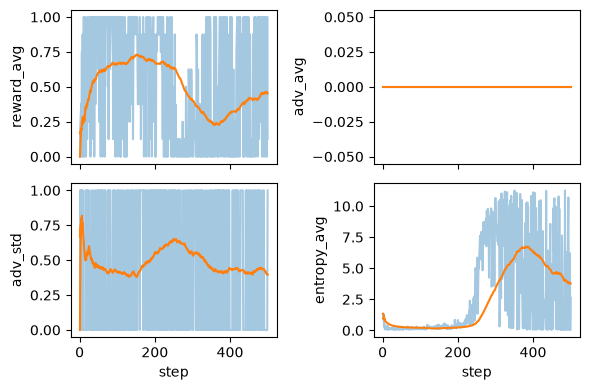

In [22]:
download_from_github(
    'ch07/02_logs/7_3_plus_tracking_metrics.csv' 
)
plot_grpo_metrics(
    '7_3_plus_tracking_metrics.csv',
    columns = ['reward_avg', 'adv_avg', 'adv_std', 'entropy_avg']
)

In [23]:
rewards = torch.tensor([1., 1., 0., 0.])

logprobs = torch.tensor([-7.9243, -20.1546, -16.6130, -23.3677])
                        
advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-4)

pg_loss = -(advantages.detach() * logprobs).mean()
print('policy gradient loss:', pg_loss)

policy gradient loss: tensor(-2.5764)


In [24]:
new_logps = logprobs 

old_logps = torch.tensor([
    -10.9243,       #  -7.9243
    -20.3546,       #  -20.1546
    -14.6130,       #  -16.6130
    -23.3677,       #  -23.3677
])

log_ratio = new_logps - old_logps 
ratio = torch.exp(log_ratio)
clip_eps = 10.0
clipped_ratio = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps)

print('ratio:        ', ratio)
print('clipped ratio:', clipped_ratio)

ratio:         tensor([20.0855,  1.2214,  0.1353,  1.0000])
clipped ratio: tensor([11.0000,  1.2214,  0.1353,  1.0000])


In [25]:
adv = advantages.detach()

unclipped = ratio * adv 
clipped = clipped_ratio * adv 

obj = torch.minimum(unclipped, clipped)

clipped_pg_loss = -torch.mean(obj)
policy_ratio = torch.mean(ratio)

print('clipped policy gradient loss:', clipped_pg_loss)
print('policy ratio:', policy_ratio)

clipped policy gradient loss: tensor(-2.3998)
policy ratio: tensor(5.6106)


In [26]:
download_from_github(
    'ch07/03_rlvr_grpo_scripts_advanced/7_4_plus_clip_ratio.py'
)

7_4_plus_clip_ratio.py: 19.1 KB (cached)


PosixPath('7_4_plus_clip_ratio.py')

In [27]:
# ! uv run 7_4_plus_clip_ratio.py \
#     --steps 500 \
#     --max_new_tokens 1024 \
#     --show_eta

7_4_plus_clip_ratio_metrics.csv: 42.7 KB (cached)


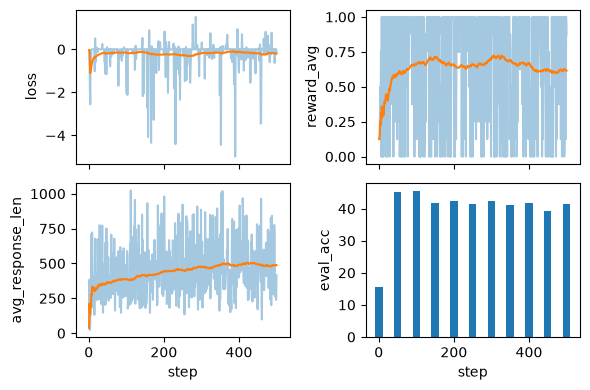

In [28]:
download_from_github(
"ch07/02_logs/7_4_plus_clip_ratio_metrics.csv"
)
plot_grpo_metrics(
"7_4_plus_clip_ratio_metrics.csv",
columns=["loss", "reward_avg", "avg_response_len", "eval_acc"]
)

In [29]:
import copy 

kl_coeff = 0.0 

if kl_coeff:
    ref_model = copy.deepcopy(model).to(device)
    ref_model.eval()
    for p in ref_model.parameters():
        p.requires_grad = False 
else:
    ref_model = None 
        
def compute_grpo_loss_with_kl(
    model,
    ref_model,
    tokenizer,
    example,
    device,
    num_rollouts = 2,
    max_new_tokens = 256,
    temperature = 0.8,
    top_p = 0.9,
    kl_coeff = 0.02,
):
    
    roll_logps, roll_ref_logps, roll_rewards, samples = [], [], [], []
    prompt = render_prompt(example['problem'])
    
    was_training = model.training
    model.eval()
    
    for _ in range(num_rollouts):
        token_ids, prompt_len, text = sample_response(
            model = model,
            tokenizer = tokenizer,
            prompt = prompt,
            device = device,
            max_new_tokens = max_new_tokens,
            temperature = temperature ,
            top_p = top_p,
        )
        
        if kl_coeff:
            with torch.no_grad():
                ref_logp = sequence_logprob(
                    ref_model, token_ids, prompt_len
                )
        else:
            ref_logp = None
        
        reward = reward_rlvr(text, example['answer'])
        
        logp = sequence_logprob(model, token_ids, prompt_len)
        
        roll_rewards.append(reward)
        roll_logps.append(logp)
        
        if kl_coeff:
            roll_ref_logps.append(ref_logp)
            
        samples.append(
            {
                'text': text,
                'reward': reward,
                'gen_len': token_ids.numel() - prompt_len,
            }
        )
        
    if was_training:
        model.train()
    
    rewards = torch.tensor(roll_rewards, device = device)
    advantages = (rewards - rewards.mean()) / (rewards.std() + 1e-4)
    
    logps = torch.stack(roll_logps)
    
    if kl_coeff:
        ref_logps = torch.stack(roll_ref_logps).detach()
        
    pg_loss = -(advantages.detach() * logps).mean()
    
    if kl_coeff:
        kl_loss = kl_coeff * torch.mean(logps - ref_logps)
    else:
        kl_loss = torch.tensor(0.0, device = logps.device)
        
    loss = pg_loss + kl_loss

In [30]:
download_from_github(
"ch07/03_rlvr_grpo_scripts_advanced/7_5_plus_kl.py"
)

7_5_plus_kl.py: 20.8 KB (cached)


PosixPath('7_5_plus_kl.py')

In [31]:
# !uv run 7_5_plus_kl.py \
# --steps 500 \
# --max_new_tokens 1024

7_5_plus_kl_metrics.csv: 48.8 KB (cached)


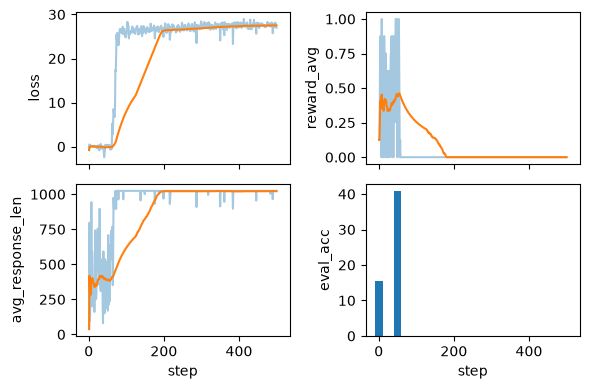

In [32]:
download_from_github(
"ch07/02_logs/"
"7_5_plus_kl_metrics.csv"
)
plot_grpo_metrics(
"7_5_plus_kl_metrics.csv",
columns=["loss", "reward_avg", "avg_response_len", "eval_acc"]
)

In [33]:
from reasoning_from_scratch.ch02 import get_device
from reasoning_from_scratch.ch03 import load_model_and_tokenizer 

device = get_device()
model, tokenizer_base = load_model_and_tokenizer(
    which_model = 'base',
    device = device,
    use_compile = False 
)

print(tokenizer_base.encode('<think>'))

Using Apple Silicon GPU (MPS)
✓ qwen3/qwen3-0.6B-base.pth already up-to-date
[13708, 766, 29]


In [34]:
tokenizer_base._tok.add_special_tokens(
    ['<tool_response>', '</tool_response>', '<think>', '</think>']
)

4

In [35]:
print(tokenizer_base.encode('<think>'))
print(tokenizer_base.encode('</think>'))

[151667]
[151668]


In [36]:
print('vocabulary size:', model.tok_emb.weight.shape[0])

vocabulary size: 151936


In [37]:
from reasoning_from_scratch.qwen3 import Qwen3Tokenizer
from reasoning_from_scratch.qwen3 import download_qwen3_small

download_qwen3_small(
    kind = 'reasoning', tokenizer_only = True, out_dir = 'qwen3' 
)

tokenizer_path = Path('qwen3') / 'tokenizer-reasoning.json' 
tokenizer = Qwen3Tokenizer(tokenizer_file_path = tokenizer_path)

print(tokenizer.encode('<think>'))
print(tokenizer.encode('</think>'))

✓ qwen3/tokenizer-reasoning.json already up-to-date
[151667]
[151668]


In [42]:
def reward_format(
    token_ids,
    prompt_len,
    start_think_id = 151667,
    end_think_id = 151668,
):
    try:
        gen = token_ids[prompt_len:].tolist()
        return float(
            gen.index(start_think_id) < gen.index(end_think_id)
        )
    except ValueError:
        return 0.0

In [44]:
prompt = 'Calculate ...' 
rollout = "Let's ... <think> ... </think>" 
token_ids = tokenizer.encode(prompt + rollout)
reward_format(
    token_ids = torch.tensor(token_ids), 
    prompt_len = len(tokenizer.encode(prompt))
)

1.0

In [45]:
download_from_github(
"ch07/03_rlvr_grpo_scripts_advanced/7_6_plus_format_reward.py"
)

7_6_plus_format_reward.py: 23.2 KB


7_6_plus_format_reward_metrics.csv: 51.7 KB


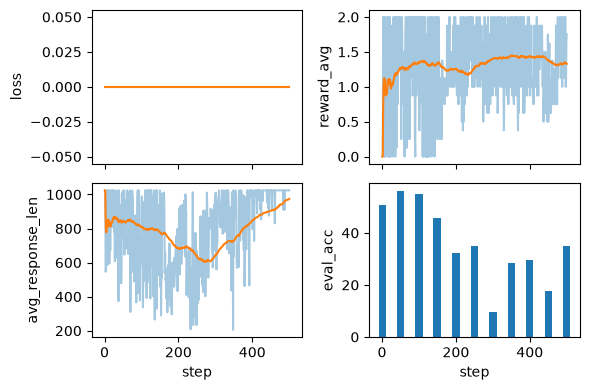

In [46]:
download_from_github(
"ch07/02_logs/7_6_plus_format_reward_metrics.csv"
)
plot_grpo_metrics(
"7_6_plus_format_reward_metrics.csv",
columns=["loss", "reward_avg", "avg_response_len", "eval_acc"]
)

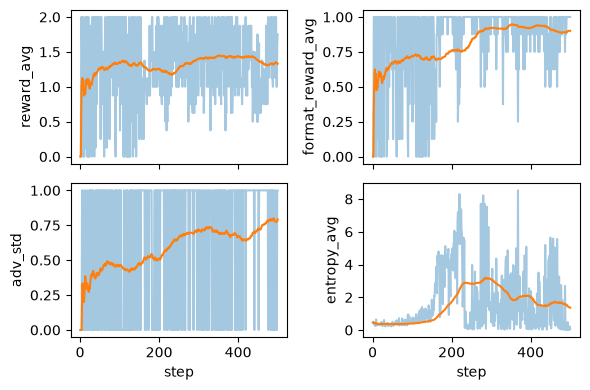

In [47]:
plot_grpo_metrics(
"7_6_plus_format_reward_metrics.csv",
columns=["reward_avg", "format_reward_avg", "adv_std", "entropy_avg"],
)